# 6 фундаментальных элементов (II): Streaming и RTAP

**Тема №23:** Анализ и прогноз погоды — *«Погода как знак и алгоритм»*

| Элемент | Формулировка в карточке темы | Что делаем в этом ноутбуке |
|---|---|---|
| **Streaming** | данные метеодатчиков можно обрабатывать в реальном времени для обновления прогноза (Spark Streaming / InfluxDB) | моделируем суточный поток со станции Кишинёва за 2024–2025: каждая запись обрабатывается сразу — признаки, прогноз, запись в базу временных рядов |
| **RTAP** (Real-Time Analytical Processing) | система адаптирует прогнозы и тревоги к изменению условий; модуль автоматических уведомлений | коды предупреждений (зелёный/жёлтый/оранжевый/красный) с автоматическими уведомлениями, контроль датчиков с автоматической коррекцией, стратегии переобучения модели |

Код компонентов находится в `src/streaming.py`.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import seaborn as sns
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from db import load_daily, load_dataset
from features import weather_type, FEATURES, TARGET, TARGET3, WEATHER_TYPES
from streaming import (sensor_stream, TimeSeriesStore, SensorHealthMonitor, SpatialConsistencyCheck, AlertEngine,
                       Notifier, StreamProcessor, StaticPolicy, PeriodicPolicy, DriftPolicy, LEVELS)
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, brier_score_loss

FIG = ROOT / "figures"; STREAM_DIR = ROOT / "data" / "stream"
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
C3 = ["#4CAF50", "#F2A93B", "#D32F2F"]
C_LEVEL = ["#DDDDDD", "#F5D33B", "#F08A24", "#D32F2F"]     # green (no warning) / yellow / orange / red
SEED = 42

def save(name):
    plt.savefig(FIG / f"{name}.png"); plt.show()

raw = load_daily("chisinau")         # the stream replays the daily measurements stored in the warehouse
data = load_dataset("chisinau")
train = data[data.date.dt.year <= 2022]; valid = data[data.date.dt.year == 2023]; test = data[data.date.dt.year >= 2024]

bundle = joblib.load(ROOT / "models" / "baseline_model.joblib")
rain_model, THR = bundle["model"], bundle["threshold"]
rain_model.set_params(n_jobs=1)          # in the stream we predict one row at a time — no parallelisation overhead
clim = train.groupby(train.date.dt.month)[TARGET].mean().to_dict()
STREAM_START, STREAM_END = "2024-01-01", "2025-12-30"
print(f"Модель осадков: {bundle['model_name']}, порог {THR:.2f}")

Модель осадков: Random Forest, порог 0.23


---
## 1. Архитектура системы

Реальная система прогноза в реальном времени состоит из компонентов ниже. Для простоты и воспроизводимости на ноутбуке поток **моделируется на Python**, но у каждого компонента есть прямой аналог в продакшене:

| Компонент (`src/streaming.py`) | Роль | Аналог в продакшене |
|---|---|---|
| `sensor_stream` | станция отправляет по одной записи (итоги дня) | IoT-датчики → **MQTT** / **Apache Kafka** |
| `StreamProcessor` | сразу обрабатывает каждую запись: признаки → прогноз → тревога | **Spark Structured Streaming** |
| `TimeSeriesStore` | хранит наблюдения, прогнозы и результаты с временными метками | **InfluxDB** (база временных рядов) |
| `SensorHealthMonitor`, `SpatialConsistencyCheck` | контроль качества: зависшие датчики, невозможные значения, раскалиброванный барометр | правила *data quality* в потоке |
| `AlertEngine` + `Notifier` | коды предупреждений и автоматические уведомления | бот **Telegram** / SMS / e-mail / webhook |
| политики адаптации | переобучение модели (периодическое или при дрейфе) | **Airflow** + **MLflow** |
| — | визуализация | **Grafana** |

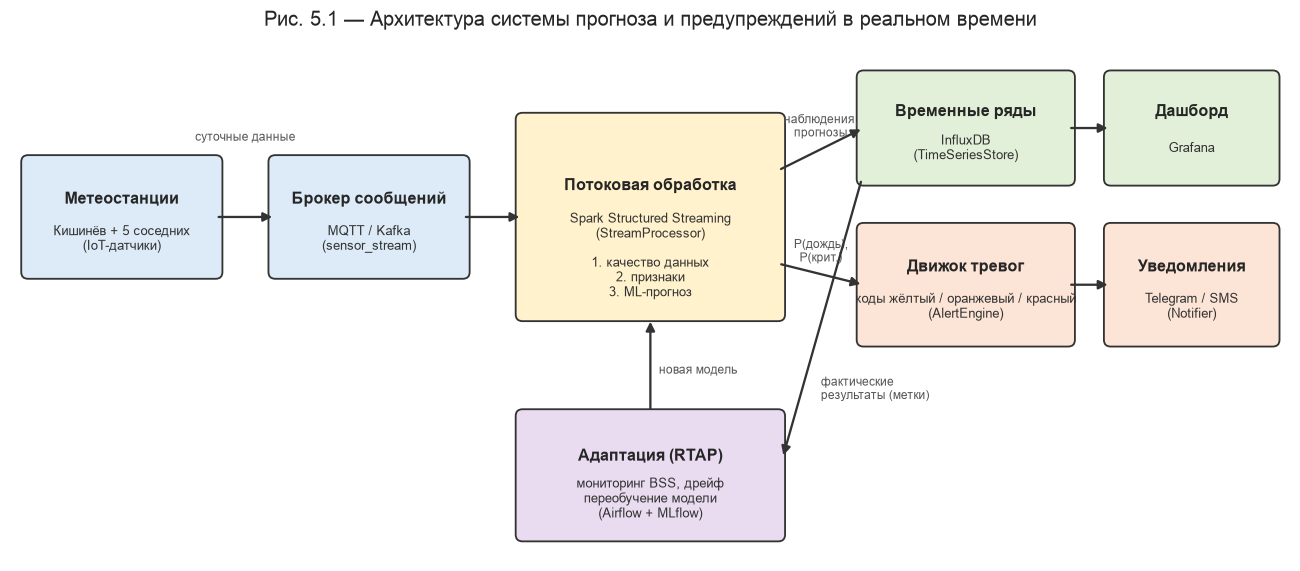

In [2]:
fig, ax = plt.subplots(figsize=(15, 6.2)); ax.set_xlim(0, 15); ax.set_ylim(0, 6.2); ax.axis("off")
def box(x, y, w, h, title, sub, color):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h * 0.66, title, ha="center", va="center", fontsize=10.5, fontweight="bold")
    ax.text(x + w / 2, y + h * 0.3, sub, ha="center", va="center", fontsize=8.5, color="#333333")
def arrow(x1, y1, x2, y2, text=""):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#333333"))
    if text: ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.15, text, ha="center", fontsize=8, color="#555555")
box(0.2, 3.4, 2.2, 1.3, "Метеостанции", "Кишинёв + 5 соседних\n(IoT-датчики)", "#DCEBF7")
box(3.1, 3.4, 2.2, 1.3, "Брокер сообщений", "MQTT / Kafka\n(sensor_stream)", "#DCEBF7")
box(6.0, 2.9, 3.0, 2.3, "Потоковая обработка", "Spark Structured Streaming\n(StreamProcessor)\n\n1. качество данных\n2. признаки\n3. ML-прогноз", "#FFF2CC")
box(10.0, 4.5, 2.4, 1.2, "Временные ряды", "InfluxDB\n(TimeSeriesStore)", "#E2F0D9")
box(10.0, 2.6, 2.4, 1.3, "Движок тревог", "коды жёлтый / оранжевый / красный\n(AlertEngine)", "#FCE4D6")
box(12.9, 4.5, 1.9, 1.2, "Дашборд", "Grafana", "#E2F0D9")
box(12.9, 2.6, 1.9, 1.3, "Уведомления", "Telegram / SMS\n(Notifier)", "#FCE4D6")
box(6.0, 0.3, 3.0, 1.4, "Адаптация (RTAP)", "мониторинг BSS, дрейф\nпереобучение модели\n(Airflow + MLflow)", "#EADCF0")
arrow(2.4, 4.05, 3.1, 4.05); arrow(5.3, 4.05, 6.0, 4.05)
ax.text(2.75, 4.95, "суточные данные", ha="center", fontsize=8, color="#555555")
arrow(9.0, 4.6, 10.0, 5.1, "наблюдения,\nпрогнозы"); arrow(9.0, 3.5, 10.0, 3.25, "P(дождь),\nP(крит.)")
arrow(12.4, 5.1, 12.9, 5.1); arrow(12.4, 3.25, 12.9, 3.25)
arrow(9.98, 4.5, 9.05, 1.2); ax.text(9.5, 1.9, "фактические\nрезультаты (метки)", ha="left", fontsize=8, color="#555555")
arrow(7.5, 1.75, 7.5, 2.85); ax.text(7.6, 2.2, "новая модель", fontsize=8, color="#555555")
ax.set_title("Рис. 5.1 — Архитектура системы прогноза и предупреждений в реальном времени", fontsize=13)
save("fig_5_1_architecture")

**Пример: та же логика в Spark Structured Streaming** (эскиз, здесь не выполняется):

```python
from pyspark.sql import SparkSession, functions as F
spark = SparkSession.builder.appName("meteo-stream").getOrCreate()

obs = (spark.readStream.format("kafka")
         .option("kafka.bootstrap.servers", "broker:9092").option("subscribe", "meteo.daily").load()
         .select(F.from_json(F.col("value").cast("string"), schema).alias("r")).select("r.*"))

def process_batch(batch_df, batch_id):
    pdf = batch_df.toPandas()                       # new records
    feats = compute_features(history.append(pdf))   # the same function as in src/features.py
    p = model.predict_proba(feats[FEATURES])[:, 1]
    write_to_influxdb(pdf, p); send_alerts(pdf, p)

obs.writeStream.foreachBatch(process_batch).option("checkpointLocation", "/chk/meteo").start()
```

---
## 2. Подготовка: модели и пороги предупреждений

Система использует две модели:
- **модель осадков** (Random Forest из ноутбука 02) → **жёлтый код**, если P(осадки) ≥ порога, выбранного на валидации;
- **модель типа погоды** (Random Forest на 3 класса с `class_weight="balanced"`, лучшая стратегия из ноутбука 03) → **оранжевый / красный код** по P(критическая погода).

Пороги для критической погоды выбираются на валидационном 2023 году:
- **оранжевый** — порог, максимизирующий F1 для критического класса (баланс между пропусками и ложными тревогами);
- **красный** — более строгий порог: наименьший порог, при котором на валидации подтвердилась хотя бы половина тревог (Precision ≥ 0.5); если такого порога нет, красный код выдаётся только для **2 %** самых высоких вероятностей (≈ 7 дней в году).

In [3]:
crit_model = clone(rain_model).set_params(class_weight="balanced", n_jobs=-1).fit(train[FEATURES], train[TARGET3])
crit_model.set_params(n_jobs=1)
pc_va = crit_model.predict_proba(valid[FEATURES])[:, 2]
is_crit_va = (valid[TARGET3] == 2).astype(int)

grid = np.round(np.arange(0.05, 0.95, 0.01), 2)
f1s = [f1_score(is_crit_va, pc_va >= t) for t in grid]
THR_ORANGE = grid[int(np.argmax(f1s))]
prec_ok = [t for t in grid if (pc_va >= t).sum() >= 3 and precision_score(is_crit_va, pc_va >= t) >= 0.5]
RED_RULE = "Precision ≥ 0.5 на валидации" if prec_ok else "2 % самых высоких вероятностей (порога с Precision ≥ 0.5 нет)"
THR_RED = min(prec_ok) if prec_ok else float(np.round(np.quantile(pc_va, 0.98), 2))
THR_RED = max(THR_RED, THR_ORANGE + 0.05)
print(f"Критических дней в валидации (2023): {is_crit_va.sum()}")
print(f"Жёлтый порог     (P осадков):     {THR:.2f}")
print(f"Оранжевый порог  (P критической): {THR_ORANGE:.2f}  — F1 крит. на валидации = {max(f1s):.3f}")
print(f"Красный порог    (P критической): {THR_RED:.2f}  — правило: {RED_RULE}; Precision на валидации = "
      f"{precision_score(is_crit_va, pc_va >= THR_RED):.2f}, дней = {(pc_va >= THR_RED).sum()}")
alerts = AlertEngine(thr_rain=THR, thr_orange=THR_ORANGE, thr_red=THR_RED)

Критических дней в валидации (2023): 24
Жёлтый порог     (P осадков):     0.23
Оранжевый порог  (P критической): 0.54  — F1 крит. на валидации = 0.286
Красный порог    (P критической): 0.63  — правило: 2 % самых высоких вероятностей (порога с Precision ≥ 0.5 нет); Precision на валидации = 0.22, дней = 9


**Пространственный контроль барометра.** Вычисляем медианное давление 5 соседних станций и «нормальную» разницу между Кишинёвом и ними (на обучающих данных).

In [4]:
NEIGHBORS = ["ungheni", "comrat", "balti", "soroca", "cahul"]
nb_pressure = pd.DataFrame({c: load_daily(c).set_index("date").pressure_msl_mean for c in NEIGHBORS}).median(axis=1)
diff = raw.set_index("date").pressure_msl_mean - nb_pressure
diff_tr = diff[diff.index.year <= 2022]
NORMAL_DIFF = diff_tr.mean()
r7 = diff_tr.rolling(7).mean()
print(f"Разница Кишинёв − медиана соседей (2015–2022): среднее {NORMAL_DIFF:+.2f} гПа, суточное стандартное отклонение {diff_tr.std():.2f} гПа")
print(f"Среднее за 7 дней отклонялось от нормы максимум на {(r7 - NORMAL_DIFF).abs().max():.2f} гПа за 8 лет "
      f"→ порог тревоги: 3 гПа")

Разница Кишинёв − медиана соседей (2015–2022): среднее -0.12 гПа, суточное стандартное отклонение 0.67 гПа
Среднее за 7 дней отклонялось от нормы максимум на 1.31 гПа за 8 лет → порог тревоги: 3 гПа


---
## 3. Streaming: прогон потока 2024–2025

Чтобы проверить и модуль контроля качества, в поток **внесены две неисправности** (системе о них неизвестно):
1. **Раскалиброванный барометр** начиная с 01.07.2024: +6 гПа (например, при перекалибровке на ~50 м ошибочно задана высота станции);
2. **Зависший гигрометр** с 01.03.2025 по 14.03.2025: всё время передаёт одно и то же значение.

Полная система: контроль качества + автоматическая коррекция барометра + прогноз + тревоги + уведомления + хранение.

In [5]:
OFFSET, OFFSET_START = 6.0, "2024-07-01"
STUCK_START, STUCK_END = "2025-03-01", "2025-03-14"
P_COLS = ["pressure_msl_mean", "pressure_msl_max", "pressure_msl_min"]

def inject_faults(raw_in, offset=OFFSET, stuck=True):
    r = raw_in.copy()
    if offset:
        m = r.date >= OFFSET_START
        r.loc[m, P_COLS] = r.loc[m, P_COLS] + offset
    if stuck:
        m = r.date.between(STUCK_START, STUCK_END)
        r.loc[m, "relative_humidity_2m_mean"] = r.loc[r.date == STUCK_START, "relative_humidity_2m_mean"].iloc[0]
    return r

raw_faulty = inject_faults(raw)
store = TimeSeriesStore(STREAM_DIR / "weather_stream.db")
notifier = Notifier(STREAM_DIR / "notifications.log", min_level=2)
proc = StreamProcessor(rain_model=rain_model, thr_rain=THR, climatology=clim,
                       history_raw=raw_faulty[raw_faulty.date < STREAM_START],
                       crit_model=crit_model, alerts=alerts, store=store, notifier=notifier,
                       health=SensorHealthMonitor(stuck_days=3),
                       spatial=SpatialConsistencyCheck(nb_pressure, NORMAL_DIFF, threshold=3.0),
                       auto_correct=True, policy=StaticPolicy())

t0 = time.perf_counter()
stream = pd.DataFrame([proc.process(rec) for rec in sensor_stream(raw_faulty, STREAM_START, STREAM_END)])
elapsed = time.perf_counter() - t0
lat = np.array(proc.latencies) * 1000
print(f"Обработано {len(stream)} записей за {elapsed:.1f} с  →  {len(stream) / elapsed:.0f} записей/с")
print(f"Задержка на запись: медиана {np.median(lat):.1f} мс, p95 {np.percentile(lat, 95):.1f} мс, максимум {lat.max():.1f} мс")
print("\nСодержимое базы временных рядов:"); print(store.count().to_string())

Обработано 730 записей за 12.6 с  →  58 записей/с
Задержка на запись: медиана 17.1 мс, p95 18.0 мс, максимум 38.1 мс

Содержимое базы временных рядов:
forecasts       730
observations    730
outcomes        729


In [6]:
# an "InfluxDB" query: the forecasts of one week
store.query("forecasts", "2025-03-08", "2025-03-14").round({"p_rain": 3, "p_crit": 3})

,ts,model_version,p_rain,p_crit,level,sensor_issues
0,2025-03-08,0,0.075,0.041,0,2
1,2025-03-09,0,0.146,0.123,0,2
2,2025-03-10,0,0.232,0.174,1,2
3,2025-03-11,0,0.341,0.270,1,2
4,2025-03-12,0,0.324,0.167,1,2
5,2025-03-13,0,0.420,0.469,1,2
6,2025-03-14,0,0.358,0.342,1,2


In [7]:
outc = store.query("outcomes")
stream_metrics = {"ROC-AUC": roc_auc_score(outc.y, outc.p_rain), "F1": f1_score(outc.y, outc.pred),
                  "Recall": recall_score(outc.y, outc.pred), "Precision": precision_score(outc.y, outc.pred),
                  "Brier": brier_score_loss(outc.y, outc.p_rain)}
print(f"Качество прогноза в потоке ({len(outc)} оценённых прогнозов):")
pd.Series(stream_metrics).round(3).to_frame("Значение")

Качество прогноза в потоке (729 оценённых прогнозов):


,Значение
ROC-AUC,0.793
F1,0.523
Recall,0.764
Precision,0.398
Brier,0.137


**Проверка корректности потока.** На чистых данных прогнозы, вычисленные день за днём (из буфера в 8 дней), должны быть **идентичны** прогнозам, вычисленным пакетно в ноутбуке 02 — иначе модель получала бы при эксплуатации другие признаки, чем при обучении (*training–serving skew*).

In [8]:
_check = StreamProcessor(rain_model=rain_model, thr_rain=THR, climatology=clim, history_raw=raw[raw.date < STREAM_START])
p_stream = np.array([_check.process(rec)["p_rain"] for rec in sensor_stream(raw, STREAM_START, STREAM_END)])
p_batch = rain_model.predict_proba(test[FEATURES])[:, 1]
print(f"Максимальная разница поток vs. пакет: {np.abs(p_stream - p_batch).max():.2e}  →  "
      + ("идентичны ✔" if np.allclose(p_stream, p_batch) else "РАЗЛИЧАЮТСЯ ✘"))

Максимальная разница поток vs. пакет: 0.00e+00  →  идентичны ✔


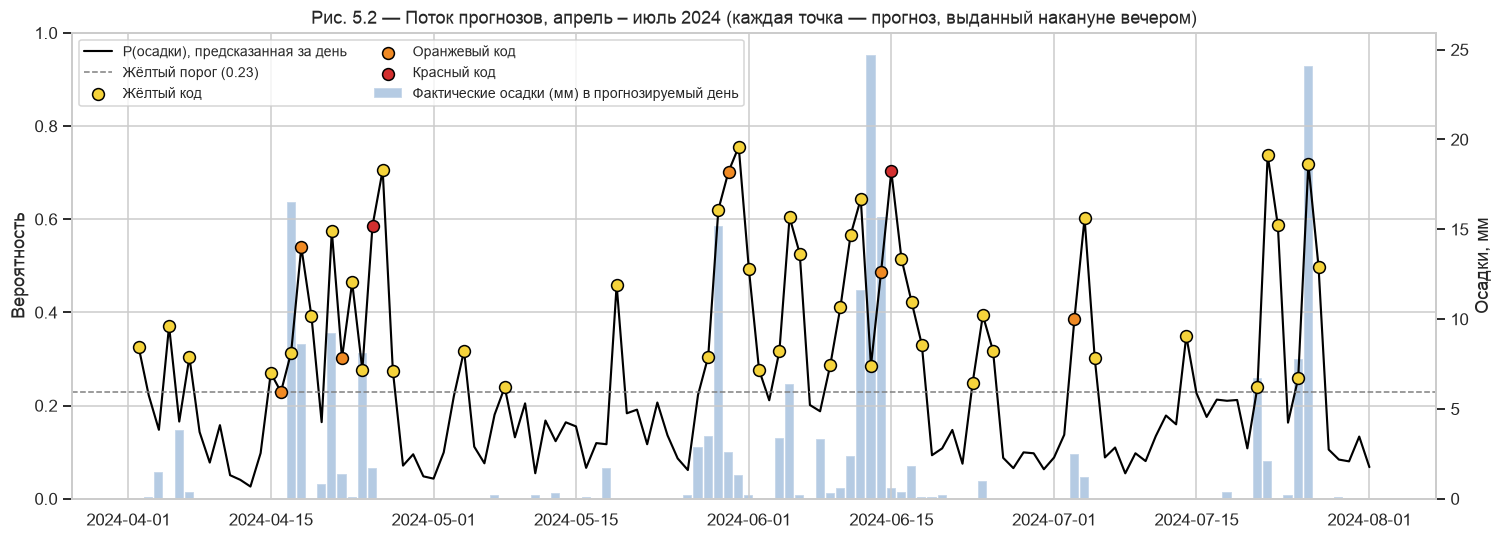

In [9]:
nxt = raw.set_index("date").precipitation_sum.shift(-1)
w = stream[(stream.date >= "2024-04-01") & (stream.date <= "2024-07-31")].copy()
w["precip_next"] = w.date.map(nxt)
fig, ax = plt.subplots(figsize=(16, 5.5))
ax2 = ax.twinx()
ax2.bar(w.date + pd.Timedelta(days=1), w.precip_next, color="#2B6CB0", alpha=0.35, width=0.9, label="Фактические осадки (мм) в прогнозируемый день")
ax2.set_ylabel("Осадки, мм"); ax2.grid(False)
ax.plot(w.date + pd.Timedelta(days=1), w.p_rain, color="black", lw=1.4, label="P(осадки), предсказанная за день")
ax.axhline(THR, ls="--", color="gray", lw=1, label=f"Жёлтый порог ({THR:.2f})")
for lvl in (1, 2, 3):
    m = w.level == lvl
    ax.scatter(w.date[m] + pd.Timedelta(days=1), w.p_rain[m], s=60, color=C_LEVEL[lvl], edgecolor="black", zorder=5,
               label=f"{LEVELS[lvl]} код")
ax.set_ylim(0, 1); ax.set_ylabel("Вероятность"); ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9, ncol=2)
ax.set_title("Рис. 5.2 — Поток прогнозов, апрель – июль 2024 (каждая точка — прогноз, выданный накануне вечером)")
save("fig_5_2_stream_timeline")

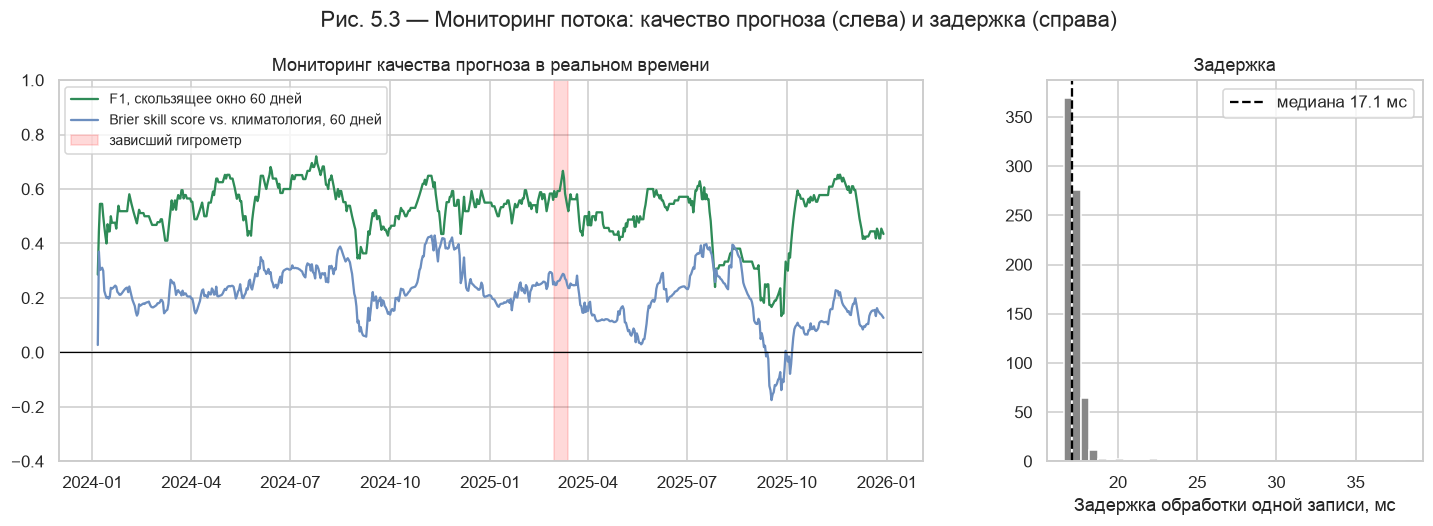

In [10]:
o = outc.set_index("ts").sort_index()
def rolling_metric(o, days, fn):
    vals = []
    for t in o.index:
        s = o.loc[t - pd.Timedelta(days=days - 1):t]
        vals.append(fn(s) if s.y.nunique() == 2 else np.nan)
    return pd.Series(vals, index=o.index)
clim_p = o.index.map(lambda d: clim[(d + pd.Timedelta(days=1)).month])
o = o.assign(p_clim=np.asarray(clim_p))
roll = pd.DataFrame({
    "f1_60": rolling_metric(o, 60, lambda s: f1_score(s.y, s.pred)),
    "bss_60": rolling_metric(o, 60, lambda s: 1 - brier_score_loss(s.y, s.p_rain) / brier_score_loss(s.y, s.p_clim)),
})
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2.3, 1]})
a1.plot(roll.index, roll.f1_60, color="#2E8B57", label="F1, скользящее окно 60 дней")
a1.plot(roll.index, roll.bss_60, color="#6C8EBF", label="Brier skill score vs. климатология, 60 дней")
a1.axhline(0, color="black", lw=0.8); a1.axvspan(pd.Timestamp(STUCK_START), pd.Timestamp(STUCK_END), color="red", alpha=0.15, label="зависший гигрометр")
a1.set_ylim(-0.4, 1); a1.legend(loc="upper left", fontsize=9); a1.set_title("Мониторинг качества прогноза в реальном времени")
a2.hist(lat, bins=40, color="#888888"); a2.axvline(np.median(lat), color="black", ls="--", label=f"медиана {np.median(lat):.1f} мс")
a2.set(xlabel="Задержка обработки одной записи, мс", title="Задержка"); a2.legend()
fig.suptitle("Рис. 5.3 — Мониторинг потока: качество прогноза (слева) и задержка (справа)", y=1.02)
save("fig_5_3_monitoring")

**Интерпретация.**
- Поток из 730 дней обрабатывается **запись за записью** с задержкой порядка **15–20 мс** на запись (признаки + 2 модели + контроль качества + запись в базу). Для станции, отправляющей данные раз в сутки (или даже раз в минуту), это огромный запас; производительность ~60 записей/с позволила бы обслуживать десятки станций на одном ядре.
- Прогнозы в потоке **идентичны** пакетным из ноутбука 02 (разница 0), значит *training–serving skew* нет: при эксплуатации модель получает ровно те же признаки, что при обучении.
- Даже с двумя внесёнными неисправностями качество прогноза в потоке остаётся на уровне ноутбука 02 (ROC-AUC ≈ 0.79, F1 ≈ 0.52, Recall ≈ 0.76) — благодаря автоматической коррекции барометра (раздел 5).
- **Рис. 5.2:** вероятность растёт перед дождливыми эпизодами (например, середина июня 2024), а в сухие периоды (май 2024, июль 2024) остаётся ниже порога.
- **Рис. 5.3:** Brier skill score за 60 дней почти всё время положительный (модель лучше климатологии), но в сентябре–октябре 2025 опускается ниже 0 — период, когда модель была слабее простой месячной статистики. Именно этот сигнал запускает переобучение в политике «при дрейфе» (раздел 6). F1 за 60 дней колеблется от ~0.3 до ~0.7, с минимумами летом (конвективные ливни).

---
## 4. RTAP (I): предупреждения и автоматические уведомления
### 4.1 Оценка кодов предупреждений

In [11]:
real_type = weather_type(raw).set_axis(raw.date).shift(-1)
s = stream.assign(real=stream.date.map(real_type)).dropna(subset=["real"]).astype({"real": int})
ct = pd.crosstab(s.level.map(dict(enumerate(LEVELS))), s.real.map(dict(enumerate(WEATHER_TYPES))))
ct = ct.reindex(index=LEVELS, columns=WEATHER_TYPES, fill_value=0)
ct["Всего"] = ct.sum(axis=1)
display(ct.rename_axis(index="Выданный код", columns="Фактическая погода (завтра)"))

crit_days = s.real == 2
alert_eval = pd.Series({
    "Реальных критических дней": int(crit_days.sum()),
    "… с оранжевым или красным кодом": int((s.level[crit_days] >= 2).sum()),
    "… хотя бы с жёлтым кодом": int((s.level[crit_days] >= 1).sum()),
    "Выдано оранжевых/красных кодов": int((s.level >= 2).sum()),
    "… подтвердились как критическая погода": int(((s.level >= 2) & crit_days).sum()),
    "… подтвердились хотя бы как неблагоприятная": int(((s.level >= 2) & (s.real >= 1)).sum()),
    "Выдано красных кодов": int((s.level == 3).sum()),
    "… красных, подтвердившихся как критическая": int(((s.level == 3) & crit_days).sum()),
    "Оранжевых/красных уведомлений в месяц (в среднем)": round((s.level >= 2).sum() / 24, 1),
}, name="Значение")
alert_eval.to_frame()

Фактическая погода (завтра),Благоприятная,Неблагоприятная,Критическая,Всего
Выданный код,,,,
Зелёный,276,128,13,417
Жёлтый,121,120,34,275
Оранжевый,6,16,6,28
Красный,2,4,4,10


,Значение
Реальных критических дней,57.0
… с оранжевым или красным кодом,10.0
… хотя бы с жёлтым кодом,44.0
Выдано оранжевых/красных кодов,38.0
… подтвердились как критическая погода,10.0
… подтвердились хотя бы как неблагоприятная,30.0
Выдано красных кодов,10.0
"… красных, подтвердившихся как критическая",4.0
Оранжевых/красных уведомлений в месяц (в среднем),1.6


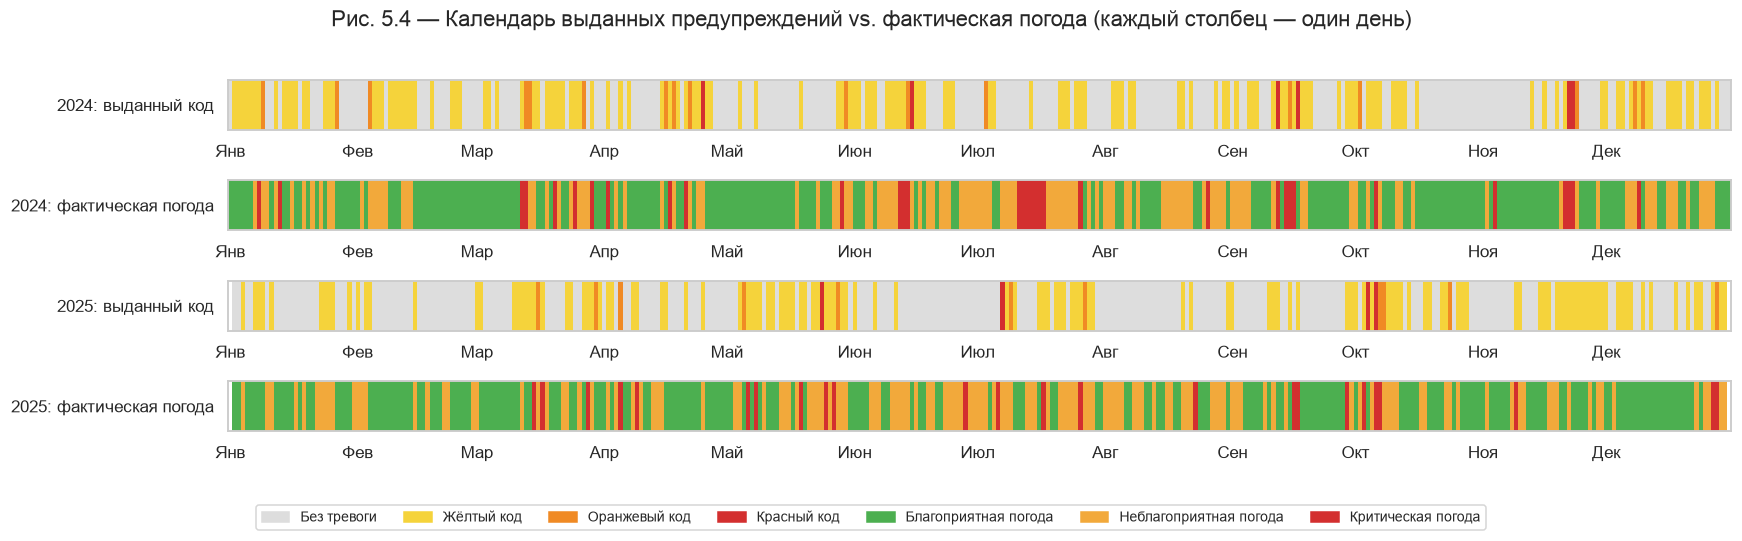

In [12]:
fig, axes = plt.subplots(4, 1, figsize=(16, 4.2), sharex=False)
for i, year in enumerate([2024, 2025]):
    sy = s[s.date.dt.year == year]
    doy = (sy.date + pd.Timedelta(days=1)).dt.dayofyear.values
    lvl_row = np.full(367, np.nan); typ_row = np.full(367, np.nan)
    lvl_row[doy] = sy.level.values; typ_row[doy] = sy.real.values
    axes[2 * i].imshow(lvl_row[None, 1:], aspect="auto", cmap=ListedColormap(C_LEVEL), vmin=-0.5, vmax=3.5)
    axes[2 * i + 1].imshow(typ_row[None, 1:], aspect="auto", cmap=ListedColormap(C3), vmin=-0.5, vmax=2.5)
    axes[2 * i].set_yticks([0], [f"{year}: выданный код"]); axes[2 * i + 1].set_yticks([0], [f"{year}: фактическая погода"])
month_starts = pd.date_range("2024-01-01", periods=12, freq="MS").dayofyear - 1
for ax in axes:
    ax.set_xticks(month_starts, ["Янв", "Фев", "Мар", "Апр", "Май", "Июн", "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"])
    ax.grid(False)
handles = ([mpatches.Patch(color=C_LEVEL[k], label=f"{LEVELS[k]} код" if k else "Без тревоги") for k in range(4)]
           + [mpatches.Patch(color=C3[k], label=f"{WEATHER_TYPES[k]} погода") for k in range(3)])
fig.legend(handles=handles, loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.12), fontsize=9)
fig.suptitle("Рис. 5.4 — Календарь выданных предупреждений vs. фактическая погода (каждый столбец — один день)", y=1.02)
plt.tight_layout(); save("fig_5_4_alert_calendar")

**Интерпретация.**
- **Жёлтый код** (вероятные осадки) хорошо работает как широкий фильтр: **44 из 57** критических дней (77 %) предварялись хотя бы жёлтым кодом; лишь 13 критических дней пришли совсем без предупреждения.
- **Оранжевый/красный коды** выдавать правильно гораздо сложнее: только **10 из 57** критических дней (18 %) были объявлены оранжевым/красным, а из 38 выданных оранжевых/красных кодов как критическая погода подтвердились лишь 10. Зато **30 из 38** (79 %) подтвердились хотя бы как неблагоприятная погода — тревоги «преувеличивают тяжесть», но редко возникают на пустом месте.
- Частота: в среднем **1.6 оранжевых/красных уведомления в месяц** — темп, который не «утомляет» пользователей.
- **Честный вывод:** по суточным данным одной точки система довольно хорошо говорит, **будет ли** непогода, но плохо — **насколько сильной** она будет. Реальные предупреждения об опасных явлениях опираются на численные модели, радары и спутники; наша модель может быть **первым фильтром**, а не заменой метеослужбы.

### 4.2 Примеры автоматических уведомлений (журнал `data/stream/notifications.log`)

In [13]:
log = pd.DataFrame(notifier.sent)
KIND_RU = {"alert": "тревога", "technical": "техническое"}
print(f"Отправлено уведомлений: {len(log)}  ({log.kind.map(KIND_RU).value_counts().to_dict()})")
pd.set_option("display.max_colwidth", 260)
examples = pd.concat([log[(log.kind == "alert") & (log.level == LEVELS[3])].head(2),
                      log[(log.kind == "alert") & (log.level == LEVELS[2])].head(2),
                      log[log.kind == "technical"].drop_duplicates("message").head(4)])
examples.assign(date=examples.date.dt.date, kind=examples.kind.map(KIND_RU)).rename(
    columns={"date": "Дата", "kind": "Тип", "level": "Уровень", "message": "Сообщение"})

Отправлено уведомлений: 598  ({'техническое': 560, 'тревога': 38})


,Дата,Тип,Уровень,Сообщение
9,2024-04-24,тревога,Красный,"КРАСНЫЙ КОД на 25.04.2024: P(осадки) = 59%, P(критическая погода) = 65%. Причины: низкое давление (1006 гПа); ветер восточного–южного направления (влажный воздух). Введите план действий в чрезвычайной ситуации; оповестите население; избегайте лишних поездок."
12,2024-06-14,тревога,Красный,"КРАСНЫЙ КОД на 15.06.2024: P(осадки) = 70%, P(критическая погода) = 65%. Причины: сплошная облачность (98 %); воздух близок к насыщению; ветер восточного–южного направления (влажный воздух). Введите план действий в чрезвычайной ситуации; оповестите населен..."
0,2024-01-08,тревога,Оранжевый,"ОРАНЖЕВЫЙ КОД на 09.01.2024: P(осадки) = 28%, P(критическая погода) = 57%. Причины: сплошная облачность (100 %); воздух близок к насыщению. Отложите полевые работы и мероприятия на открытом воздухе; подготовьте аварийные службы."
1,2024-01-26,тревога,Оранжевый,"ОРАНЖЕВЫЙ КОД на 27.01.2024: P(осадки) = 27%, P(критическая погода) = 62%. Причины: давление упало на 12.5 гПа за 3 дня; сплошная облачность (95 %); воздух близок к насыщению; сильный ветер сегодня (32 км/ч). Отложите полевые работы и мероприятия на открыт..."
14,2024-07-03,техническое,—,Барометр раскалиброван: отклонение +3.0 гПа от соседних станций — применена автоматическая коррекция — проверьте станцию; доверие к прогнозу снижено.
15,2024-07-04,техническое,—,Барометр раскалиброван: отклонение +3.8 гПа от соседних станций — применена автоматическая коррекция — проверьте станцию; доверие к прогнозу снижено.
16,2024-07-05,техническое,—,Барометр раскалиброван: отклонение +4.6 гПа от соседних станций — применена автоматическая коррекция — проверьте станцию; доверие к прогнозу снижено.
17,2024-07-06,техническое,—,Барометр раскалиброван: отклонение +5.4 гПа от соседних станций — применена автоматическая коррекция — проверьте станцию; доверие к прогнозу снижено.


**Интерпретация.**
- Каждое уведомление объясняет, **почему** оно выдано (низкое или падающее давление, сплошная облачность, насыщенный воздух, ветер сектора В–Ю), и **что делать** — пользователь доверяет тревоге, которую понимает.
- Примеры показывают и ограничение системы: за красными кодами на 25.04.2024 и 15.06.2024 последовала **неблагоприятная** (дождь, порывы 53 км/ч), а не критическая погода, а оранжевый код на 27.01.2024 оказался **ложной тревогой** (благоприятная погода), хотя давление упало на 12.5 гПа за 3 дня.
- Технические уведомления о барометре повторяются каждый день (546 сообщений). В продакшене их нужно **дедуплицировать**: одно сообщение при обнаружении, затем ежедневная сводка до устранения неисправности.

---
## 5. RTAP (II): обнаружение неисправностей и автоматическое вмешательство

In [14]:
tech = log[log.kind == "technical"]
first_baro = tech[tech.message.str.startswith("Барометр раскалиброван")].date.min()
hygro = tech[tech.message.str.startswith("Гигрометр завис")]
stuck_msgs = hygro[hygro.date.between(STUCK_START, STUCK_END)]
false_flags = pd.concat([tech[(tech.date < OFFSET_START) & tech.message.str.startswith("Барометр")],
                         tech[~tech.message.str.startswith("Барометр") & ~(tech.message.str.startswith("Гигрометр") &
                                                                         tech.date.between(STUCK_START, STUCK_END))]])
print(f"Барометр раскалиброван с {OFFSET_START} → обнаружено {first_baro.date()} "
      f"(задержка {(first_baro - pd.Timestamp(OFFSET_START)).days} дня); оценка смещения при обнаружении: "
      f"{stream.loc[stream.date == first_baro, 'offset'].iloc[0]:+.2f} гПа")
print(f"Гигрометр завис {STUCK_START} – {STUCK_END} → первая тревога {stuck_msgs.date.min().date()}, "
      f"тревоги каждый день до {stuck_msgs.date.max().date()} ({len(stuck_msgs)} тревог)")
print(f"Барометр: {len(tech[tech.message.str.startswith('Барометр')])} ежедневных тревог (неисправность длится до конца потока)")
print(f"Ложных технических тревог (вне внесённых неисправностей): {len(false_flags)}")
false_flags[["date", "message"]].assign(date=false_flags.date.dt.date).rename(columns={"date": "Дата", "message": "Сообщение"})

Барометр раскалиброван с 2024-07-01 → обнаружено 2024-07-03 (задержка 2 дня); оценка смещения при обнаружении: +3.02 гПа
Гигрометр завис 2025-03-01 – 2025-03-14 → первая тревога 2025-03-03, тревоги каждый день до 2025-03-14 (12 тревог)
Барометр: 546 ежедневных тревог (неисправность длится до конца потока)
Ложных технических тревог (вне внесённых неисправностей): 2


,Дата,Сообщение
541,2025-11-07,Гигрометр завис: значение 85.0 не менялось 3 дня подряд — проверьте станцию; доверие к прогнозу снижено.
543,2025-11-08,Гигрометр завис: значение 85.0 не менялось 3 дня подряд — проверьте станцию; доверие к прогнозу снижено.


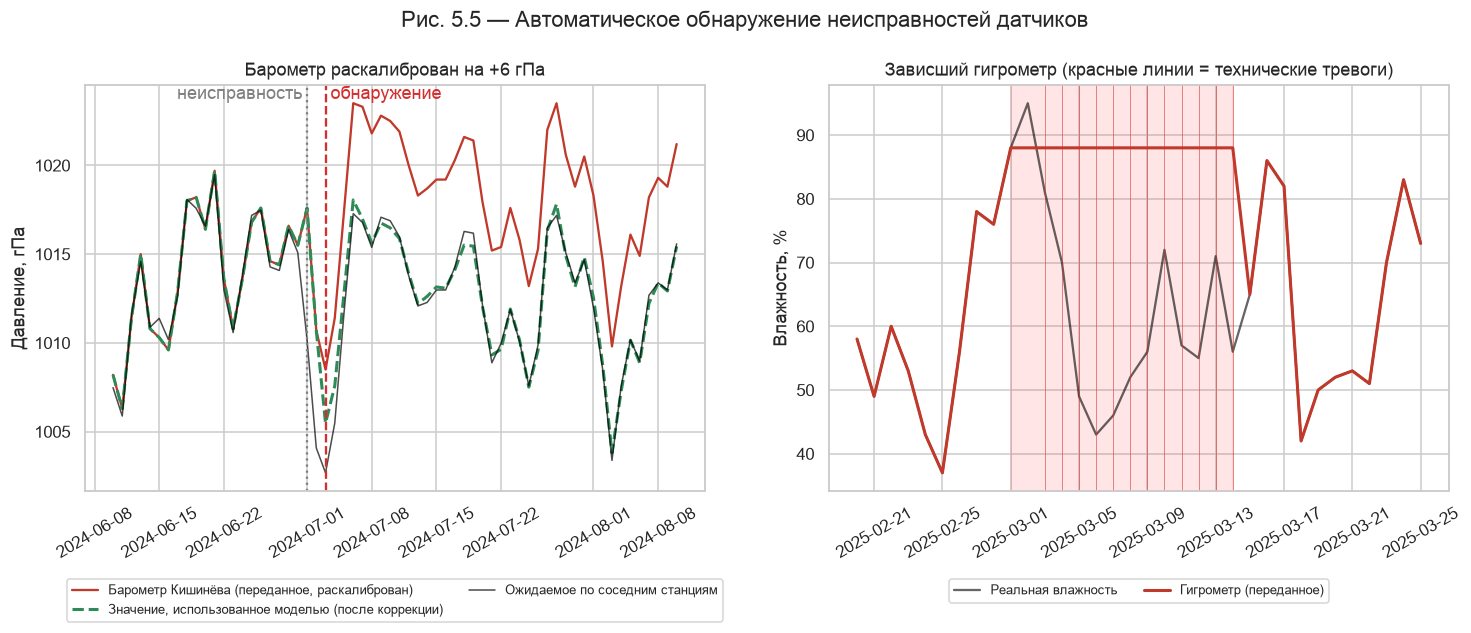

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.8))
w = stream[(stream.date >= "2024-06-10") & (stream.date <= "2024-08-10")]
a1.plot(w.date, w.pressure_raw, color="#C0392B", lw=1.5, label="Барометр Кишинёва (переданное, раскалиброван)")
a1.plot(w.date, w.pressure_used, color="#2E8B57", lw=2, ls="--", label="Значение, использованное моделью (после коррекции)")
a1.plot(w.date, nb_pressure.reindex(w.date).values + NORMAL_DIFF, color="black", lw=1, alpha=0.7, label="Ожидаемое по соседним станциям")
ytop = a1.get_ylim()[1]
a1.axvline(pd.Timestamp(OFFSET_START), color="gray", ls=":"); a1.text(pd.Timestamp(OFFSET_START), ytop - 0.8, "неисправность ", color="gray", ha="right")
a1.axvline(first_baro, color="#D32F2F", ls="--"); a1.text(first_baro, ytop - 0.8, " обнаружение", color="#D32F2F")
a1.set(ylabel="Давление, гПа", title="Барометр раскалиброван на +6 гПа")
a1.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
a1.tick_params(axis="x", rotation=30)
w2 = raw_faulty[(raw_faulty.date >= "2025-02-20") & (raw_faulty.date <= "2025-03-25")]
a2.plot(w2.date, raw.set_index("date").relative_humidity_2m_mean.reindex(w2.date).values, color="black", alpha=0.6, label="Реальная влажность")
a2.plot(w2.date, w2.relative_humidity_2m_mean, color="#C0392B", lw=2, label="Гигрометр (переданное)")
a2.axvspan(pd.Timestamp(STUCK_START), pd.Timestamp(STUCK_END), color="red", alpha=0.1)
for d in hygro.date[hygro.date.between("2025-02-20", "2025-03-25")]: a2.axvline(d, color="#D32F2F", lw=0.6, alpha=0.6)
a2.set(ylabel="Влажность, %", title="Зависший гигрометр (красные линии = технические тревоги)")
a2.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
a2.tick_params(axis="x", rotation=30)
fig.suptitle("Рис. 5.5 — Автоматическое обнаружение неисправностей датчиков", y=1.02)
save("fig_5_5_sensor_faults")

**Эффект автоматического вмешательства.** Прогоняем один и тот же поток с раскалиброванным барометром дважды: с автоматической коррекцией и без неё (и, для сравнения, с исправным барометром).

In [16]:
def run(raw_in, policy=None, spatial=False, auto_correct=False):
    p = StreamProcessor(rain_model=rain_model, thr_rain=THR, climatology=clim, history_raw=raw_in[raw_in.date < STREAM_START],
                        policy=policy or StaticPolicy(),
                        spatial=SpatialConsistencyCheck(nb_pressure, NORMAL_DIFF) if spatial else None, auto_correct=auto_correct)
    t0 = time.perf_counter()
    for rec in sensor_stream(raw_in, STREAM_START, STREAM_END):
        p.process(rec)
    o = pd.DataFrame(p.outcomes, columns=["date", "p", "y", "p_clim"])
    return p, o, {"ROC-AUC": roc_auc_score(o.y, o.p), "F1": f1_score(o.y, o.p >= THR), "Recall": recall_score(o.y, o.p >= THR),
                  "Brier": brier_score_loss(o.y, o.p), "Средняя вероятность": o.p.mean(), "Реальная частота": o.y.mean(),
                  "Переобучений": len(p.retrains), "Время, с": time.perf_counter() - t0}

raw_offset = inject_faults(raw, stuck=False)
ic = {}
_, _, ic["Исправный барометр"] = run(raw)
_, _, ic["Барометр +6 гПа, без вмешательства"] = run(raw_offset)
_, _, ic["Барометр +6 гПа, автоматическая коррекция"] = run(raw_offset, spatial=True, auto_correct=True)
ic = pd.DataFrame(ic).T.drop(columns=["Переобучений", "Время, с"])
ic.round(4)

,ROC-AUC,F1,Recall,Brier,Средняя вероятность,Реальная частота
Исправный барометр,0.7941,0.5203,0.7578,0.1363,0.2367,0.2209
"Барометр +6 гПа, без вмешательства",0.7871,0.5199,0.6894,0.1382,0.2082,0.2209
"Барометр +6 гПа, автоматическая коррекция",0.7935,0.5245,0.7640,0.1365,0.2371,0.2209


**Интерпретация.**
- **Раскалиброванный барометр** обнаружен **через 2 дня** сравнением давления с соседними станциями. Оценка смещения растёт в первую неделю (+3.0 → +6 гПа), пока заполняется 7-дневное окно, после чего коррекция становится практически точной (зелёная пунктирная линия совпадает с ожидаемым значением на рис. 5.5).
- **Эффект автоматического вмешательства:** без коррекции модель «видит» слишком высокое давление → считает погоду более устойчивой → **занижает** вероятность дождя (0.208 против реальной частоты 0.221) и пропускает больше дождей (Recall 0.69 вместо 0.76, т. е. ~12 дополнительно пропущенных дождливых дней). С коррекцией все метрики возвращаются к уровню исправного барометра.
- **Зависший гигрометр** обнаружен начиная с третьего дня и сигнализировался каждый день до конца неисправности (12 тревог). Вне внесённых неисправностей было лишь **2 ложные тревоги за 2 года** (ноябрь 2025: влажность ровно 85 % три дня подряд — влажность записывается целыми процентами, поэтому совпадение возможно).
- **Урок RTAP:** правильная реакция на неисправность датчика — не переобучение модели, а **контроль входных данных** — см. раздел 6.

---
## 6. RTAP (III): адаптация модели — стратегии переобучения

Погода и датчики меняются со временем (*concept drift*). Сравниваем четыре политики переобучения модели осадков в потоке:
- **Статичная** — модель 2022 года больше не меняется;
- **Ежемесячно, расширяющееся окно** — в начале каждого месяца переобучение на всей истории;
- **Ежемесячно, скользящее окно 3 года** — только на последних 3 годах (забывает далёкое прошлое);
- **При дрейфе** — переобучение только тогда, когда **Brier skill score** за последние 60 дней падает ниже 0, т. е. модель становится хуже простой климатологии.

Проверяем их в двух сценариях: **A** — исправные датчики; **B** — барометр раскалиброван на +6 гПа с июля 2024, без пространственной коррекции (адаптация должна сама «обнаружить» проблему).

In [17]:
SCEN_A, SCEN_B = "A: исправные датчики", "B: барометр +6 гПа"
SPATIAL = "Статичная + пространственная коррекция"
policies = [StaticPolicy(), PeriodicPolicy(), PeriodicPolicy(window_years=3), DriftPolicy(window=60, min_bss=0.0)]
adapt_rows, adapt_runs = [], {}
for scen, raw_in in {SCEN_A: raw, SCEN_B: raw_offset}.items():
    for pol in policies:
        p, o, m = run(raw_in, policy=pol)
        adapt_rows.append({"Сценарий": scen, "Политика": pol.name, **m})
        adapt_runs[(scen, pol.name)] = (p, o)
    p, o, m = run(raw_in, spatial=True, auto_correct=True)
    adapt_rows.append({"Сценарий": scen, "Политика": SPATIAL, **m})
    adapt_runs[(scen, SPATIAL)] = (p, o)
adapt = pd.DataFrame(adapt_rows).set_index(["Сценарий", "Политика"])
adapt.round(4)

ROC-AUC      F1  \
Сценарий             Политика                                                  
A: исправные датчики Статичная (без переобучения)             0.7941  0.5203   
                     Ежемесячно, расширяющееся окно           0.7966  0.5247   
                     Ежемесячно, скользящее окно 3 года       0.7901  0.4979   
                     При дрейфе (BSS за 60 дн. < 0.0)         0.7917  0.5225   
                     Статичная + пространственная коррекция   0.7941  0.5203   
B: барометр +6 гПа   Статичная (без переобучения)             0.7871  0.5199   
                     Ежемесячно, расширяющееся окно           0.7873  0.5175   
                     Ежемесячно, скользящее окно 3 года       0.7770  0.4917   
                     При дрейфе (BSS за 60 дн. < 0.0)         0.7841  0.5152   
                     Статичная + пространственная коррекция   0.7935  0.5245   

                                                             Recall   Brier  \
Сценарий             Политика                                                 
A: исправные датчики Статичная (без переобучения)            0.7578  0.1363   
                     Ежемесячно, расширяющееся окно          0.7578  0.1356   
                     Ежемесячно, скользящее окно 3 года      0.7205  0.1397   
                     При дрейфе (BSS за 60 дн. < 0.0)        0.7578  0.1366   
                     Статичная + пространственная коррекция  0.7578  0.1363   
B: барометр +6 гПа   Статичная (без переобучения)            0.6894  0.1382   
                     Ежемесячно, расширяющееся окно          0.6894  0.1381   
                     Ежемесячно, скользящее окно 3 года      0.6460  0.1420   
                     При дрейфе (BSS за 60 дн. < 0.0)        0.6832  0.1385   
                     Статичная + пространственная коррекция  0.7640  0.1365   

                                                             Средняя вероятность  \
Сценарий             Политика                                                      
A: исправные датчики Статичная (без переобучения)                         0.2367   
                     Ежемесячно, расширяющееся окно                       0.2336   
                     Ежемесячно, скользящее окно 3 года                   0.2310   
                     При дрейфе (BSS за 60 дн. < 0.0)                     0.2368   
                     Статичная + пространственная коррекция               0.2367   
B: барометр +6 гПа   Статичная (без переобучения)                         0.2082   
                     Ежемесячно, расширяющееся окно                       0.2073   
                     Ежемесячно, скользящее окно 3 года                   0.2081   
                     При дрейфе (BSS за 60 дн. < 0.0)                     0.2089   
                     Статичная + пространственная коррекция               0.2371   

                                                             Реальная частота  \
Сценарий             Политика                                                   
A: исправные датчики Статичная (без переобучения)                      0.2209   
                     Ежемесячно, расширяющееся окно                    0.2209   
                     Ежемесячно, скользящее окно 3 года                0.2209   
                     При дрейфе (BSS за 60 дн. < 0.0)                  0.2209   
                     Статичная + пространственная коррекция            0.2209   
B: барометр +6 гПа   Статичная (без переобучения)                      0.2209   
                     Ежемесячно, расширяющееся окно                    0.2209   
                     Ежемесячно, скользящее окно 3 года                0.2209   
                     При дрейфе (BSS за 60 дн. < 0.0)                  0.2209   
                     Статичная + пространственная коррекция            0.2209   

                                                             Переобучений  \
Сценарий             Политика                                               
A: исправные да

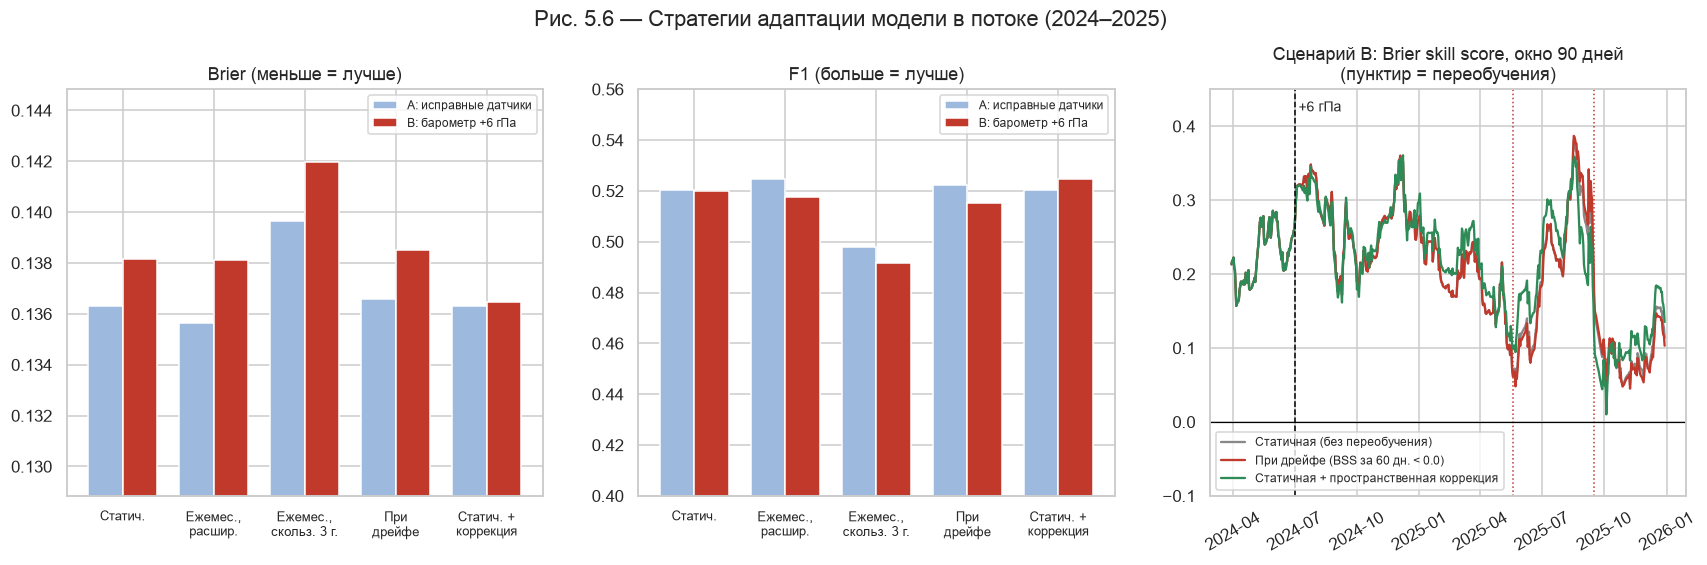

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
pol_names = adapt.index.get_level_values(1).unique()
short = {policies[0].name: "Статич.", policies[1].name: "Ежемес.,\nрасшир.", policies[2].name: "Ежемес.,\nскольз. 3 г.",
         policies[3].name: "При\nдрейфе", SPATIAL: "Статич. +\nкоррекция"}
for ax, metric in zip(axes[:2], ["Brier", "F1"]):
    t = adapt[metric].unstack(0).loc[pol_names]
    x = np.arange(len(t)); wdt = 0.38
    ax.bar(x - wdt / 2, t[SCEN_A], wdt, color="#9DB9DE", label=SCEN_A)
    ax.bar(x + wdt / 2, t[SCEN_B], wdt, color="#C0392B", label=SCEN_B)
    ax.set_xticks(x, [short[n] for n in t.index], fontsize=8.5)
    lo = t.min().min(); ax.set_ylim(lo * 0.95 if metric == "Brier" else 0.4, t.max().max() * 1.02 if metric == "Brier" else 0.56)
    ax.set_title(metric + (" (меньше = лучше)" if metric == "Brier" else " (больше = лучше)")); ax.legend(fontsize=8)
ax = axes[2]
for pol, col in zip([policies[0].name, policies[3].name, SPATIAL], ["#888888", "#C0392B", "#2E8B57"]):
    p, o = adapt_runs[(SCEN_B, pol)]
    o = o.set_index("date")
    bss = (1 - ((o.p - o.y) ** 2).rolling(90).mean() / ((o.p_clim - o.y) ** 2).rolling(90).mean())
    ax.plot(bss.index, bss.values, color=col, label=pol)
    for r in p.retrains:
        ax.axvline(r["date"], color=col, ls=":", lw=1)
ax.axvline(pd.Timestamp(OFFSET_START), color="black", ls="--", lw=1); ax.text(pd.Timestamp(OFFSET_START), 0.42, " +6 гПа", fontsize=9)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Сценарий B: Brier skill score, окно 90 дней\n(пунктир = переобучения)", ylim=(-0.1, 0.45))
ax.legend(fontsize=8, loc="lower left"); ax.tick_params(axis="x", rotation=30)
fig.suptitle("Рис. 5.6 — Стратегии адаптации модели в потоке (2024–2025)", y=1.03)
save("fig_5_6_adaptation")

**Интерпретация.**

**Сценарий A (исправные датчики):**
- Ежемесячное переобучение на всей истории даёт **пренебрежимый** выигрыш (Brier 0.1356 против 0.1363, F1 0.525 против 0.520) ценой 24 переобучений (в ~2.7 раза дольше).
- Скользящее окно в 3 года — **самое слабое** (Brier 0.140, F1 0.50): потеря данных важнее их «свежести» — климат за несколько лет изменился не настолько, чтобы старые данные стали вредными.
- Политика **«при дрейфе»** переобучилась лишь один раз (сентябрь 2025, когда BSS стал отрицательным — см. рис. 5.3) и дала то же качество, что и статичная модель, — переобучение только когда нужно.

**Сценарий B (барометр +6 гПа):**
- **Ни одна стратегия переобучения не решает проблему** (Brier 0.138–0.142). Переобучение на испорченных данных смешивает правильные значения давления (до июня 2024) со смещёнными — модель «выучивает ошибку» лишь частично и медленно.
- Детектор дрейфа по качеству **не заметил неисправность**: BSS оставался положительным после июля 2024 (рис. 5.6, справа), потому что эффект +6 гПа мал на фоне естественной изменчивости качества прогноза. Переобучения в мае и сентябре 2025 были вызваны сезонными колебаниями, а не барометром.
- **Только пространственная коррекция** возвращает качество к уровню сценария A (Brier 0.1365).

**Вывод:** в RTAP нужно отслеживать **и входы** (качество данных, сравнение с другими источниками), **и выходы** (качество прогноза). Переобучение помогает при медленных изменениях погоды; внезапные неисправности датчиков устраняются у источника.

---
# Размышления над исследовательским вопросом

> *«Как подготовиться к тому, что мы не можем контролировать? Что говорит нам небо, прежде чем заговорить?»*

**Что говорит небо, прежде чем заговорить.** Анализ показал, что атмосфера «предупреждает» об осадках за сутки несколькими признаками: **низким и падающим давлением**, **сплошной облачностью**, **воздухом, близким к насыщению**, и **ветром восточного–южного направления** со стороны Чёрного моря. Яснее всего предупреждаются сильные осадки (≥ 10 мм) — модель обнаружила их в 97 % случаев. Но небо говорит не обо всех явлениях одинаково ясно: летние ливни формируются за несколько часов, а жара выглядит как обычный тёплый день. Хорошая модель не «слышит» всего — она **знает, чего не слышит**, и её откалиброванные вероятности (редко выше 0.75) честно сообщают, насколько велика неопределённость.

**Как подготовиться к тому, что мы не можем контролировать.** Погоду мы контролировать не можем, но можем контролировать всё, что касается системы, которая её наблюдает и интерпретирует:
- **качество данных** — раскалиброванный на 6 гПа барометр заставил модель пропустить ~12 дополнительных дождливых дней; сравнение с соседними станциями обнаружило проблему за 2 дня и автоматически её исправило;
- **пороги решений** — выбор между пропущенными дождями и ложными тревогами не технический вопрос, а вопрос **ответственности**: фермеру, организатору мероприятий и экстренной службе нужны разные пороги;
- **справедливость** — модель, обученная в столице, почти так же хорошо работает в Сороках и Кагуле, но слегка переоценивает дожди на юге; кто остаётся «невидимым», нужно проверять явно, а не предполагать;
- **адаптацию** — система должна сама следить за своим качеством и реагировать, но переобучение — не ответ на всё: иногда чинить нужно источник, а не модель.

**Ответственность специалиста по данным.** Ложная тревога стоит доверия («мальчик, который кричал „волки“»), пропущенная тревога может стоить жизней и урожая. Поэтому результаты этой работы приведены вместе с их ограничениями: что модель предсказывает хорошо (будет ли завтра дождь), что плохо (насколько опасной будет погода) и чего она не может предсказать по суточным данным одной точки.

---
# Выводы: 6 фундаментальных элементов

| Элемент | Что сделано | Главный результат |
|---|---|---|
| **Bias** | модель Кишинёва проверена в 5 населённых пунктах; частые vs. редкие паттерны; контролируемо внесённые смещения выборки и измерений | хорошая географическая справедливость (ΔF1 ≤ 0.03); сильные осадки обнаруживаются в 97 % случаев, опасность жары недооценивается; смещение осадкомера невидимо в ROC-AUC, видно только в калибровке |
| **Noise** | шум датчиков, пропуски + заполнение, зависшие датчики, ошибки в метках | плавная деградация; реалистичный шум пренебрежим; RF устойчивее LR; линейная интерполяция = утечка из будущего; критичные датчики: барометр и облачность |
| **Decision Boundaries** | 3 типа погоды; PCA, t-SNE, плоскость температура–давление; LR / SVM / RF | классы сильно перекрываются; у критической погоды два «лица» (грозы при низком давлении, жара при сухом тёплом воздухе) |
| **SMOTE** | 6 стратегий балансировки, сила SMOTE, сравнение с порогом | без балансировки критический класс не предсказывается никогда; SMOTE поднимает Recall критического класса с 0 до 0.30–0.42; `class_weight` для RF оказался ещё лучше |
| **Streaming** | суточный поток 2024–2025, база временных рядов, задержка, проверка поток = пакет | ~15–20 мс на запись; прогнозы идентичны пакетным; качество сохраняется несмотря на неисправности |
| **RTAP** | коды жёлтый/оранжевый/красный с объяснёнными уведомлениями; обнаружение и автоматическая коррекция датчиков; 4 политики переобучения | 77 % критических дней предварялись хотя бы жёлтым кодом, но лишь 18 % — оранжевым/красным; раскалиброванный барометр обнаружен за 2 дня и исправлен; переобучение при дрейфе = то же качество с 1 переобучением вместо 24 |

**Следующие шаги для итоговой работы:** перенести результаты 4 ноутбуков в главу 1 (теория, KPI) и главу 2 (6 элементов) шаблона, с рисунками из папки `figures/`, и подготовить презентацию.